## Dependencies

In [ ]:
!pip uninstall -y torch torchvision torchaudio
!pip install -U --no-cache-dir torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu126

In [ ]:
!pip install segmentation-models-pytorch -q

## Libraries

In [ ]:
import os
import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from glob import glob
from torch.utils.data import Dataset, DataLoader
from torch.cuda.amp import GradScaler, autocast
from torch.optim.lr_scheduler import CosineAnnealingLR
import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp
from tqdm import tqdm


## CONFIG FILE (Hyper Parameters)

In [ ]:
class CFG:
    # Paths
    TRAIN_IMAGE_DIR = "/kaggle/working/openearthmap/images/train"
    TRAIN_MASK_DIR  = "/kaggle/working/openearthmap/labels/train"
    VAL_IMAGE_DIR   = "/kaggle/working/openearthmap/images/val"
    VAL_MASK_DIR    = "/kaggle/working/openearthmap/labels/val"
    TEST_IMAGE_DIR  = "/kaggle/working/openearthmap/images/test"
    TEST_MASK_DIR   = "/kaggle/working/openearthmap/labels/test"
    ENCODER         = "mit_b3"
    ENCODER_WEIGHTS = "imagenet"
    NUM_CLASSES     = 9
    IMAGE_SIZE      = 512
    EPOCHS          = 20
    BATCH_SIZE      = 2
    LR              = 6e-5
    WEIGHT_DECAY    = 1e-2
    GRAD_CLIP       = 1.0
    CE_WEIGHT       = 0.5
    DICE_WEIGHT     = 0.5
    POINTS_PER_CLASS = 50
    IGNORE_INDEX     = 255
    NUM_WORKERS     = 2
    SAVE_PATH       = "best_model.pth"
    DEVICE          = "cuda" if torch.cuda.is_available() else "cpu"

print(f"Device : {CFG.DEVICE}")
print(f"Encoder: {CFG.ENCODER}")    

## Detect CUDA 

In [ ]:
DEVICE      = "cuda" if torch.cuda.is_available() else "cpu"
MODEL_PATH  = "best_model.pth"  
IMAGE_PATH  = "/kaggle/input/datasets/ahmedshayan1/test-123/images.jpeg"
IMAGE_SIZE  = 512
NUM_CLASSES = 9
ENCODER     = "mit_b3"

## Partial PE Loss and DICE Loss

In [ ]:
class PartialCombinedLoss(nn.Module):
    def __init__(self, ignore_index=255, ce_weight=0.5, dice_weight=0.5):
        super().__init__()
        self.ignore_index = ignore_index
        self.ce_weight    = ce_weight
        self.dice_weight  = dice_weight

    def forward(self, pred, target):
        valid_mask  = (target != self.ignore_index)          
        safe_target = target.clone()
        safe_target[~valid_mask] = 0                       
        log_probs        = F.log_softmax(pred, dim=1)
        target_log_probs = log_probs.gather(
            dim=1, index=safe_target.unsqueeze(1)
        ).squeeze(1)
        ce_loss   = (-target_log_probs * valid_mask.float())
        num_valid = valid_mask.sum()
        ce_loss   = ce_loss.sum() / (num_valid + 1e-8)
        probs       = F.softmax(pred, dim=1)
        num_classes = pred.shape[1]
        dice_loss   = 0.0
        valid_cls   = 0
        for cls in range(num_classes):
            cls_mask   = (target == cls).float()
            cls_pred   = probs[:, cls]
            cls_valid  = cls_mask   * valid_mask.float()
            pred_valid = cls_pred   * valid_mask.float()
            if cls_valid.sum() == 0:
                continue
            intersection = (pred_valid * cls_valid).sum()
            denom        = pred_valid.sum() + cls_valid.sum()
            dice_loss   += 1.0 - (2.0 * intersection + 1e-8) / (denom + 1e-8)
            valid_cls   += 1
        dice_loss = dice_loss / (valid_cls + 1e-8)
        return self.ce_weight * ce_loss + self.dice_weight * dice_loss

## Point Mask

In [ ]:
def create_point_mask(mask, points_per_class=50, ignore_index=255):
    point_mask = np.full_like(mask, ignore_index)
    for cls in np.unique(mask):
        coords = np.argwhere(mask == cls)
        if len(coords) == 0:
            continue
        chosen = coords[
            np.random.choice(len(coords),
                             min(points_per_class, len(coords)),
                             replace=False)
        ]
        for y, x in chosen:
            point_mask[y, x] = cls
    return point_mask

### Data set Creation

In [ ]:
class LandCoverDataset(Dataset):
    def __init__(self, image_paths, mask_paths,
                 transform=None,
                 points_per_class=50,
                 ignore_index=255):
        self.image_paths      = image_paths
        self.mask_paths       = mask_paths
        self.transform        = transform
        self.points_per_class = points_per_class
        self.ignore_index     = ignore_index

    def __len__(self):
        return len(self.image_paths)
    def __getitem__(self, idx):
        image = cv2.imread(self.image_paths[idx])
        mask  = cv2.imread(self.mask_paths[idx], cv2.IMREAD_GRAYSCALE)
        if image is None or mask is None:           
            return self.__getitem__((idx + 1) % len(self))
        image      = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        point_mask = create_point_mask(mask,
                                       self.points_per_class,
                                       self.ignore_index)
        if self.transform:
            aug        = self.transform(image=image, mask=point_mask)
            image      = aug["image"]
            point_mask = aug["mask"]

        return image, point_mask.long()

## Data Augmentation and Transformation

In [ ]:
S = CFG.IMAGE_SIZE

train_transform = A.Compose([
    A.Resize(S, S),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.Affine(translate_percent=0.05, scale=(0.9, 1.1),
             rotate=(-15, 15), p=0.5),
    A.OneOf([
        A.RandomBrightnessContrast(p=1.0),
        A.HueSaturationValue(p=1.0),
        A.CLAHE(clip_limit=4.0, p=1.0),
    ], p=0.6),
    A.GaussNoise(p=0.3),
    A.GaussianBlur(blur_limit=3, p=0.2),
    A.CoarseDropout(
        num_holes_range=(4, 8),
        hole_height_range=(16, 32),
        hole_width_range=(16, 32),
        fill=0, p=0.3
    ),
    A.Normalize(mean=(0.485, 0.456, 0.406),
                std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])
val_transform = A.Compose([
    A.Resize(S, S),
    A.Normalize(mean=(0.485, 0.456, 0.406),
                std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])

## Data Loader

In [ ]:
def build_loader(img_dir, msk_dir, transform,
                 shuffle, points_per_class):
    img_paths = sorted(glob(os.path.join(img_dir, "*.png")))
    msk_paths = sorted(glob(os.path.join(msk_dir, "*.png")))
    ds = LandCoverDataset(img_paths, msk_paths,
                          transform=transform,
                          points_per_class=points_per_class,
                          ignore_index=CFG.IGNORE_INDEX)
    return DataLoader(ds,
                      batch_size=CFG.BATCH_SIZE,
                      shuffle=shuffle,
                      num_workers=CFG.NUM_WORKERS,
                      pin_memory=True)


train_loader = build_loader(CFG.TRAIN_IMAGE_DIR, CFG.TRAIN_MASK_DIR,
                            train_transform, shuffle=True,
                            points_per_class=CFG.POINTS_PER_CLASS)
val_loader   = build_loader(CFG.VAL_IMAGE_DIR,   CFG.VAL_MASK_DIR,
                            val_transform,   shuffle=False,
                            points_per_class=CFG.POINTS_PER_CLASS)
test_loader  = build_loader(CFG.TEST_IMAGE_DIR,  CFG.TEST_MASK_DIR,
                            val_transform,   shuffle=False,
                            points_per_class=CFG.POINTS_PER_CLASS)

print(f"\nTrain batches : {len(train_loader)}")
print(f"Val   batches : {len(val_loader)}")
print(f"Test  batches : {len(test_loader)}")

## Group Normalization

In [ ]:
def bn_to_gn(module: nn.Module, num_groups: int = 16) -> nn.Module:
    for name, child in module.named_children():
        if isinstance(child, nn.BatchNorm2d):
            num_channels = child.num_features
            # fall back to 1 group if channels < num_groups
            groups = min(num_groups, num_channels)
            while num_channels % groups != 0:
                groups //= 2
            gn = nn.GroupNorm(groups, num_channels,
                              eps=child.eps, affine=child.affine)
            setattr(module, name, gn)
        else:
            bn_to_gn(child, num_groups)
    return module



## Unet Model

In [ ]:
model = smp.Unet(
    encoder_name    = CFG.ENCODER,
    encoder_weights = CFG.ENCODER_WEIGHTS,
    decoder_channels= (256, 128, 64, 32, 16),
    in_channels     = 3,
    classes         = CFG.NUM_CLASSES,
)

## Inilization

In [ ]:
bn_to_gn(model.decoder)
bn_to_gn(model.segmentation_head)
model = model.to(CFG.DEVICE)
model.eval()
with torch.no_grad():
    _x = torch.randn(1, 3, S, S).to(CFG.DEVICE)
    _y = model(_x)
    print(f"\nModel output shape: {_y.shape}")   # (1, 9, 512, 512)
del _x, _y
model.train()

### Hyper Parameters

In [ ]:
criterion = PartialCombinedLoss(
    ignore_index = CFG.IGNORE_INDEX,
    ce_weight    = CFG.CE_WEIGHT,
    dice_weight  = CFG.DICE_WEIGHT,
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr           = CFG.LR,
    weight_decay = CFG.WEIGHT_DECAY,
)

scheduler = CosineAnnealingLR(
    optimizer,
    T_max   = CFG.EPOCHS,
    eta_min = 1e-6,
)

scaler = GradScaler()

## Evalutaion Metrics

In [ ]:
def compute_metrics(preds, targets,
                    num_classes=CFG.NUM_CLASSES,
                    ignore_index=CFG.IGNORE_INDEX):
    valid  = (targets != ignore_index)
    p      = preds[valid]
    t      = targets[valid]

    pixel_acc = (p == t).float().mean().item()

    ious = []
    for cls in range(num_classes):
        pc = (p == cls)
        tc = (t == cls)
        inter = (pc & tc).sum().item()
        union = (pc | tc).sum().item()
        if union > 0:
            ious.append(inter / union)

    mean_iou = float(np.mean(ious)) if ious else 0.0
    return pixel_acc, mean_iou

### Tranning

In [ ]:
best_val_loss = float("inf")
history       = {"train_loss": [], "val_loss": [],
                 "pixel_acc": [], "mean_iou": []}

print("\n" + "="*60)
print("  TRAINING START")
print("="*60)


for epoch in range(CFG.EPOCHS):
    model.train()
    total_train_loss = 0.0
    train_bar = tqdm(train_loader,
                     desc=f"Epoch {epoch+1:02d}/{CFG.EPOCHS} [Train]",
                     leave=False)
    for images, masks in train_bar:
        images = images.to(CFG.DEVICE)
        masks  = masks.to(CFG.DEVICE)
        optimizer.zero_grad()
        with autocast():
            outputs = model(images)
            loss    = criterion(outputs, masks)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), CFG.GRAD_CLIP)
        scaler.step(optimizer)
        scaler.update()
        total_train_loss += loss.item()
        train_bar.set_postfix({"loss": f"{loss.item():.4f}"})
    avg_train_loss = total_train_loss / len(train_loader)
    model.eval()
    total_val_loss = 0.0
    pixel_accs, mean_ious = [], []
    with torch.no_grad():
        val_bar = tqdm(val_loader,
                       desc=f"Epoch {epoch+1:02d}/{CFG.EPOCHS} [Val]  ",
                       leave=False)
        for images, masks in val_bar:
            images = images.to(CFG.DEVICE)
            masks  = masks.to(CFG.DEVICE)

            with autocast():
                outputs = model(images)
                loss    = criterion(outputs, masks)

            total_val_loss += loss.item()

            preds = torch.argmax(outputs, dim=1).cpu()
            pa, mi = compute_metrics(preds, masks.cpu())
            pixel_accs.append(pa)
            mean_ious.append(mi)
    avg_val_loss  = total_val_loss / len(val_loader)
    avg_pixel_acc = float(np.mean(pixel_accs)) * 100
    avg_mean_iou  = float(np.mean(mean_ious))  * 100

    scheduler.step()
    current_lr = optimizer.param_groups[0]["lr"]
    history["train_loss"].append(avg_train_loss)
    history["val_loss"].append(avg_val_loss)
    history["pixel_acc"].append(avg_pixel_acc)
    history["mean_iou"].append(avg_mean_iou)
    print(f"\nEpoch [{epoch+1:02d}/{CFG.EPOCHS}]"
          f"  Train Loss: {avg_train_loss:.4f}"
          f"  Val Loss: {avg_val_loss:.4f}"
          f"  Pixel Acc: {avg_pixel_acc:.2f}%"
          f"  Mean IoU: {avg_mean_iou:.2f}%"
          f"  LR: {current_lr:.2e}")
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        torch.save(model.state_dict(), CFG.SAVE_PATH)
        print(f"  ✔ Best model saved  (val_loss={best_val_loss:.4f})")


### Evaluation

In [ ]:
print("\n" + "="*60)
print("  TEST EVALUATION")
print("="*60)
model.load_state_dict(torch.load(CFG.SAVE_PATH, map_location=CFG.DEVICE))
model.eval()
test_pixel_accs, test_mean_ious = [], []
with torch.no_grad():
    for images, masks in tqdm(test_loader, desc="Testing"):
        images = images.to(CFG.DEVICE)
        masks  = masks.to(CFG.DEVICE)

        with autocast():
            outputs = model(images)

        preds = torch.argmax(outputs, dim=1).cpu()
        pa, mi = compute_metrics(preds, masks.cpu())
        test_pixel_accs.append(pa)
        test_mean_ious.append(mi)

print(f"\nTest Pixel Accuracy : {np.mean(test_pixel_accs)*100:.2f}%")
print(f"Test Mean IoU       : {np.mean(test_mean_ious)*100:.2f}%")

## Tranning Curvs

In [ ]:
print("\n── Training History ──────────────────────────────────")
print(f"{'Epoch':>6} {'TrainLoss':>10} {'ValLoss':>9} "
      f"{'PixAcc%':>8} {'mIoU%':>7}")
print("-" * 46)
for i in range(len(history["train_loss"])):
    print(f"{i+1:>6} {history['train_loss'][i]:>10.4f} "
          f"{history['val_loss'][i]:>9.4f} "
          f"{history['pixel_acc'][i]:>8.2f} "
          f"{history['mean_iou'][i]:>7.2f}")

print("\nDone! Best model saved to:", CFG.SAVE_PATH)

## Single Image inference

Loaded: /kaggle/input/models/ahmedshayan1/model-12/pytorch/default/1/best_model.pth

── Predicted classes ──────────────────────────────
   0  Background        2.1%
   1  Bareland          7.2%
   2  Rangeland        18.9%
   3  Developed        10.3%
   4  Road              2.3%
   5  Tree             14.4%
   6  Water            20.7%
   7  Agriculture      22.6%
   8  Building          1.5%

Saved: prediction.png


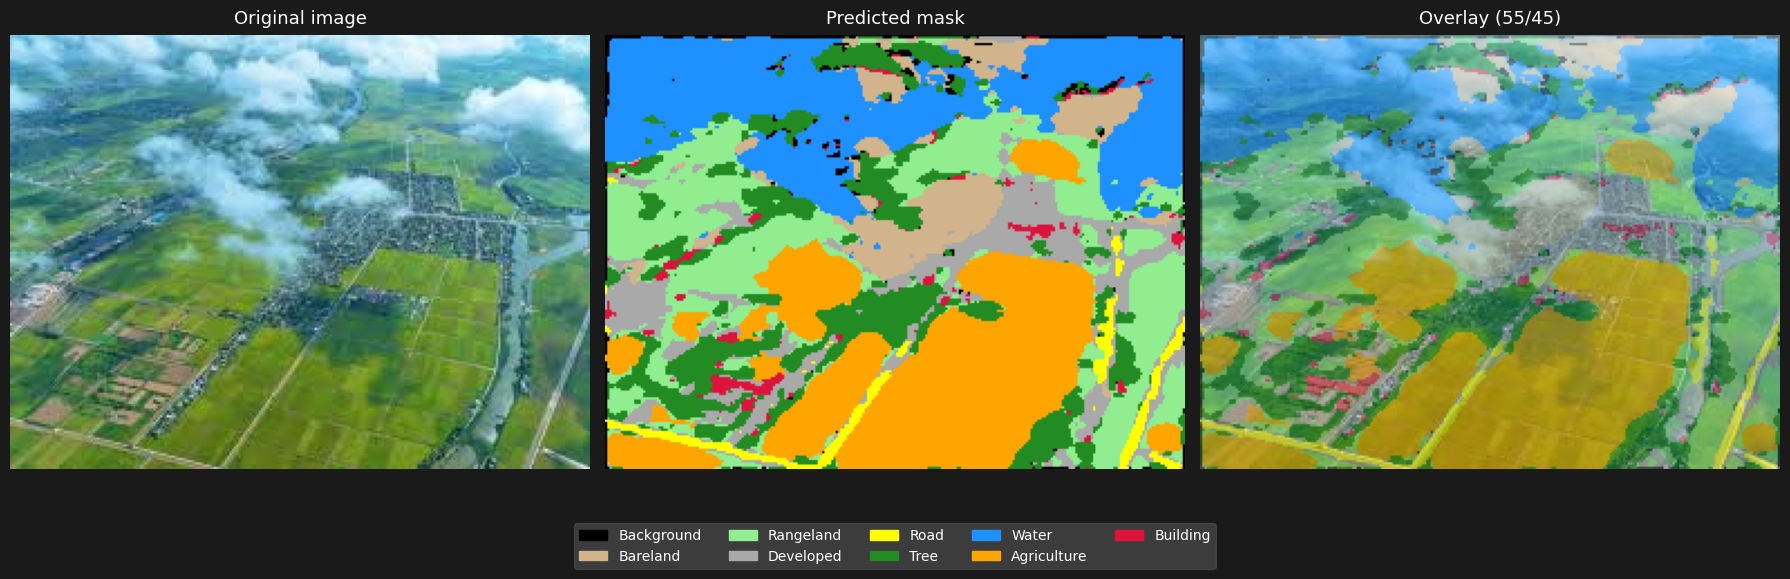

In [1]:
import cv2
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import segmentation_models_pytorch as smp
import albumentations as A
from albumentations.pytorch import ToTensorV2
DEVICE      = "cuda" if torch.cuda.is_available() else "cpu"
MODEL_PATH  = "/kaggle/input/models/ahmedshayan1/model-12/pytorch/default/1/best_model.pth"  
IMAGE_PATH  = "/kaggle/input/datasets/ahmedshayan1/test-123/images.jpeg"
IMAGE_SIZE  = 512
NUM_CLASSES = 9
ENCODER     = "mit_b3"
CLASS_NAMES = [
    "Background",    
    "Bareland",      
    "Rangeland",     
    "Developed",     
    "Road",          
    "Tree",          
    "Water",         
    "Agriculture",   
    "Building",      
]
CLASS_COLORS = np.array([
    [0,   0,   0  ],  
    [210, 180, 140],  
    [144, 238, 144],  
    [169, 169, 169],   
    [255, 255,   0], 
    [34,  139,  34],  
    [30,  144, 255],   
    [255, 165,   0],  
    [220,  20,  60],   
], dtype=np.uint8)
def bn_to_gn(module: nn.Module, num_groups: int = 16) -> nn.Module:
    for name, child in module.named_children():
        if isinstance(child, nn.BatchNorm2d):
            num_channels = child.num_features
            groups = min(num_groups, num_channels)
            while num_channels % groups != 0:
                groups //= 2
            gn = nn.GroupNorm(groups, num_channels,
                              eps=child.eps, affine=child.affine)
            setattr(module, name, gn)
        else:
            bn_to_gn(child, num_groups)
    return module
def load_model(model_path: str) -> nn.Module:
    model = smp.Unet(
        encoder_name    = ENCODER,
        encoder_weights = None,         
        decoder_channels= (256, 128, 64, 32, 16),
        in_channels     = 3,
        classes         = NUM_CLASSES,
    )
    bn_to_gn(model.decoder)
    bn_to_gn(model.segmentation_head)
    state = torch.load(model_path, map_location=DEVICE)
    model.load_state_dict(state)
    model.to(DEVICE)
    model.eval()
    print(f"Loaded: {model_path}")
    return model
preprocess = A.Compose([
    A.Resize(IMAGE_SIZE, IMAGE_SIZE),
    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std =(0.229, 0.224, 0.225)
    ),
    ToTensorV2()
])
def predict(model: nn.Module, image_path: str):
    bgr = cv2.imread(image_path)
    if bgr is None:
        raise FileNotFoundError(f"Cannot read image: {image_path}")
    orig_h, orig_w = bgr.shape[:2]
    orig_image = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    aug    = preprocess(image=orig_image)
    tensor = aug["image"].unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        with torch.amp.autocast(DEVICE):
            logits = model(tensor)
    probs     = torch.softmax(logits, dim=1)[0]   
    pred_512  = torch.argmax(probs, dim=0).cpu().numpy().astype(np.uint8)
    pred_mask = cv2.resize(
        pred_512,
        (orig_w, orig_h),
        interpolation=cv2.INTER_NEAREST   
    )
    color_mask = CLASS_COLORS[pred_mask]
    return pred_mask, color_mask, orig_image, probs.cpu().numpy()
def visualise(image_path: str, model_path: str = MODEL_PATH,
              save_path: str = None):
    model      = load_model(model_path)
    pred_mask, color_mask, orig_image, probs = predict(model, image_path)
    present_classes = np.unique(pred_mask)
    print("\n── Predicted classes ──────────────────────────────")
    for cls in present_classes:
        pct = (pred_mask == cls).mean() * 100
        print(f"  {cls:2d}  {CLASS_NAMES[cls]:<14}  {pct:5.1f}%")
    overlay = cv2.addWeighted(
        orig_image.astype(np.float32), 0.55,
        color_mask.astype(np.float32), 0.45,
        0
    ).astype(np.uint8)
    legend = [
        mpatches.Patch(
            color=CLASS_COLORS[c] / 255.0,
            label=f"{CLASS_NAMES[c]}"
        )
        for c in present_classes
    ]
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    fig.patch.set_facecolor("#1a1a1a")
    titles = ["Original image", "Predicted mask", "Overlay (55/45)"]
    imgs   = [orig_image, color_mask, overlay]
    for ax, img, title in zip(axes, imgs, titles):
        ax.imshow(img)
        ax.set_title(title, color="white", fontsize=13, pad=8)
        ax.axis("off")
        ax.set_facecolor("#1a1a1a")

    fig.legend(
        handles=legend,
        loc="lower center",
        ncol=min(len(present_classes), 5),
        framealpha=0.15,
        labelcolor="white",
        fontsize=10,
        bbox_to_anchor=(0.5, -0.04)
    )
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight",
                    facecolor=fig.get_facecolor())
        print(f"\nSaved: {save_path}")
    plt.show()
    return pred_mask, color_mask, overlay
def show_confidence(image_path: str, class_id: int,
                    model_path: str = MODEL_PATH):
    model = load_model(model_path)
    _, _, orig_image, probs = predict(model, image_path)
    conf = probs[class_id]   
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].imshow(orig_image)
    axes[0].set_title("Original", fontsize=12)
    axes[0].axis("off")
    im = axes[1].imshow(conf, cmap="RdYlGn", vmin=0, vmax=1)
    axes[1].set_title(
        f"Confidence — class {class_id}: {CLASS_NAMES[class_id]}",
        fontsize=12
    )
    axes[1].axis("off")
    plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.show()
if __name__ == "__main__":
    pred_mask, color_mask, overlay = visualise(
        image_path = IMAGE_PATH,
        model_path = MODEL_PATH,
        save_path  = "prediction.png"   # set None to skip saving
    )